# Rated power: every sensor stretched from part load to rated power (30 A) and 60 kW

**Rated power = 30 A per string = 52 kW DC** (user, 2026-11-06; was 60 kW = 40.18 A); the table still runs to 60 kW.

Part load never went above ~34 kW DC. This notebook reads every logged sensor at **0 … 60 kW** by fitting a straight
line in power on the part-load minutes, then solves the string voltages and currents so that ΣV·I really adds up to the
power, and works out the gas by Faraday.

It calls the functions in `scripts/rated_power_extrapolation.py` (the same code the command line runs) and writes the
same files to `03_data_analysis/rated_power/`.

| § | Step | Function |
|---|---|---|
| 1 | Part-load minutes, P_dc = Σ V·I over 5 strings | `pl_minutes` |
| 2 | Straight line `sensor = a + b·P` per sensor, glitch minutes dropped | `extrapolate` |
| 3 | Trust: R² and leave-one-run-out error at the top of each run | `extrapolate` |
| 4 | Electrical: V = a + b·I per string, equal string current, gas by Faraday | `electrical` |
| 4.5 | R² of every part-load fit: each changing sensor's power line and each string's V–I line | — |
| 4.6 | Curve fits (quadratic, power lag, run start + lag) per sensor: R², MAE, plots of all 464 | `rated_power_curves.py` |
| 4.7 | **Extrapolation with the best plausible curve per sensor** (these are the saved `use_*kW` values) | `apply_best`, `add_notes` |
| 5 | Notes and limits (trips, cell protection, actuators past 100 %) | — |
| 6 | Save outputs | — |

**Limit:** a straight line in power only. Part-load minutes are not steady (temperatures still rising when a run ends),
so heat-driven sensors read low; the stack and BOP temperatures need the twin heat balance (`05_twin_2d`).

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")   # helper modules live in 03_data_analysis/scripts/
import rated_power_extrapolation as rp

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, ORANGE, RED = "#2f5f9e", "#9aa4b3", "#b86e00", "#b03a2e"

rp.self_check()
print("steps (kW):", rp.STEPS, "| rated", rp.RATED_KW, "kW |", rp.CELLS, "cells per string")

steps (kW): [0, 10, 20, 30, 34, 40, 50, 52, 60] | rated 52 kW | 476 cells per string


## 1. Part-load minutes

Minutes labelled **Part load** in `plant_stages_1min.parquet`, raw 10-s data averaged to 1 min, logger dropouts (−1)
removed. DC power = Σ string voltage × string current. A *run* is an unbroken stretch of part-load minutes.

In [2]:
d = rp.pl_minutes()
runs = d.groupby("run").agg(minutes=("P_dc_kW", "size"), P_mean_kW=("P_dc_kW", "mean"), P_max_kW=("P_dc_kW", "max"))
runs.insert(0, "start", d.index.to_series().groupby(d.run.values).first())
print(f"{len(d)} part-load minutes, {d.run.nunique()} runs, P max {d.P_dc_kW.max():.1f} kW")
runs.round(1)

268 part-load minutes, 10 runs, P max 33.6 kW


,start,minutes,P_mean_kW,P_max_kW
run,,,,
1,2026-03-13 10:03:00,8,7.7,10.9
2,2026-03-13 13:26:00,17,13.9,19.1
3,2026-03-19 10:20:00,17,11.7,15.0
4,2026-03-19 15:31:00,18,16.0,21.2
5,2026-03-24 08:54:00,32,20.1,31.1
6,2026-03-24 13:54:00,43,10.7,18.7
7,2026-03-25 08:18:00,33,12.3,23.7
8,2026-03-25 10:17:00,33,17.1,25.0
9,2026-03-25 14:30:00,44,23.3,33.6


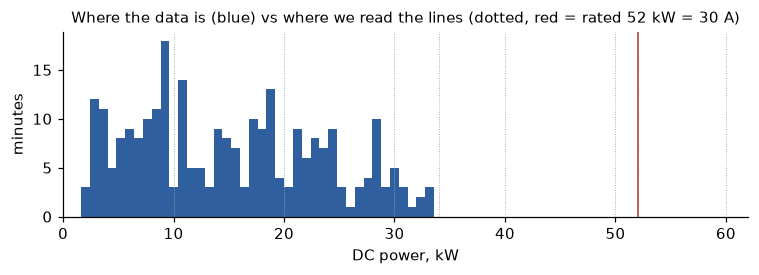

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(d.P_dc_kW, bins=40, color=BLUE)
for p in rp.STEPS:
    ax.axvline(p, color=GRAY, lw=0.6, ls=":")
ax.axvline(rp.RATED_KW, color=RED, lw=1)
ax.set_xlim(0, 62)
ax.set_xlabel("DC power, kW"); ax.set_ylabel("minutes")
ax.set_title("Where the data is (blue) vs where we read the lines (dotted, red = rated 52 kW = 30 A)", fontsize=10)
plt.tight_layout()

## 2. A straight line per sensor

For each numeric sensor with ≥ 60 minutes and some spread: fit `sensor = a + b·P`, drop minutes more than 4 robust
sigma off that line (glitches such as 93 V strings or 28 V cells), fit again and read the line at each step.

Each sensor is put in one group:
* **follows power**: R² ≥ 0.5 and the held-out error ≤ 25 % of the seen range; the line is used.
* **temperature / cell (lags power)**: physical but weak line; the line is still used, low trust.
* **operator-set / no link**: set points, modes; kept at their part-load mean.

These are the first-pass values; §4.7 replaces them with each sensor's best plausible curve.

In [4]:
t = rp.extrapolate(d)
print(len(t), "changing sensors")
t.group.value_counts().to_frame("sensors")

464 changing sensors


,sensors
group,
operator-set / no link,251
temperature / cell (lags power),145
follows power,68


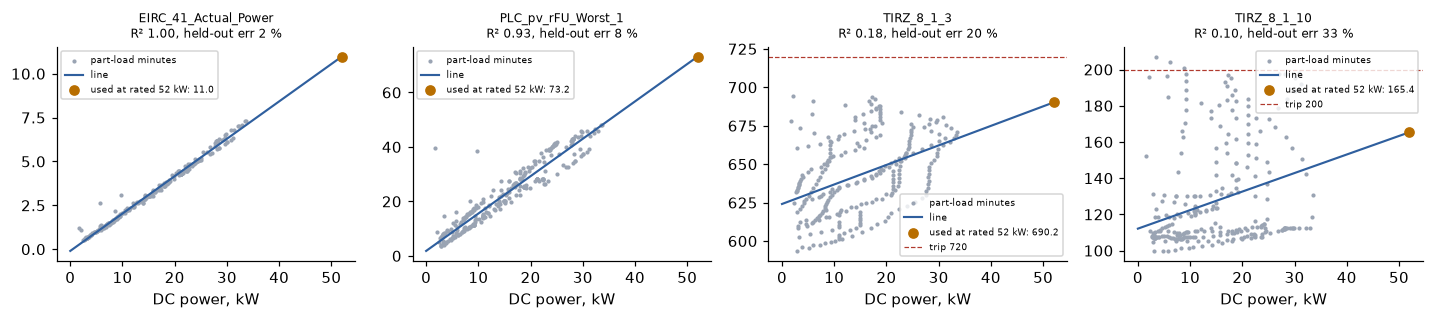

In [5]:
EXAMPLES = ["EIRC_41_Actual_Power", "PLC_pv_rFU_Worst_1", "TIRZ_8_1_3", "TIRZ_8_1_10"]
xs = np.linspace(0, rp.RATED_KW, 2)
T = t.set_index("sensor")
fig, axs = plt.subplots(1, len(EXAMPLES), figsize=(13, 3))
for ax, s in zip(axs, EXAMPLES):
    r = T.loc[s]
    ax.scatter(d.P_dc_kW, d[s], s=3, color=GRAY, label="part-load minutes")
    ax.plot(xs, r.at_0kW + r.slope_per_kW * xs, color=BLUE, lw=1.4, label="line")
    u = r[f"use_{rp.RATED_KW}kW"]
    ax.scatter([rp.RATED_KW], [u], color=ORANGE, zorder=3, label=f"used at rated {rp.RATED_KW} kW: {u:.1f}")
    if s in rp.LIMITS:
        ax.axhline(rp.LIMITS[s], color=RED, lw=0.8, ls="--", label=f"trip {rp.LIMITS[s]:.0f}")
    ax.set_title(f"{s}\nR² {r.r2:.2f}, held-out err {r.loro_err_pct_of_range:.0f} %", fontsize=8)
    ax.set_xlabel("DC power, kW"); ax.legend(fontsize=6)
plt.tight_layout()

## 3. How far can each line be trusted?

Leave one part-load run out, fit on the rest, predict the held-out run's **top-power quarter** (minutes above its
75th power percentile). The mean error, as % of the sensor's seen range, says how well the line carries past the
data it was fitted on.

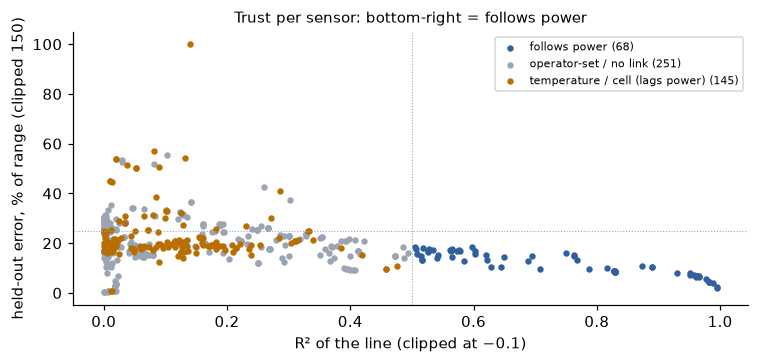

In [6]:
colors = {"follows power": BLUE, "temperature / cell (lags power)": ORANGE, "operator-set / no link": GRAY}
fig, ax = plt.subplots(figsize=(7, 3.4))
for g, sub in t.groupby("group"):
    ax.scatter(sub.r2.clip(-0.1, 1), sub.loro_err_pct_of_range.clip(0, 150), s=10, color=colors[g], label=f"{g} ({len(sub)})")
ax.axvline(0.5, color=GRAY, lw=0.7, ls=":"); ax.axhline(25, color=GRAY, lw=0.7, ls=":")
ax.set_xlabel("R² of the line (clipped at −0.1)"); ax.set_ylabel("held-out error, % of range (clipped 150)")
ax.legend(fontsize=7); ax.set_title("Trust per sensor: bottom-right = follows power", fontsize=10)
plt.tight_layout()

In [7]:
cols = ["sensor", "group", "r2", "loro_err_pct_of_range", "seen_min", "seen_max", "at_34kW", "at_60kW"]
t[t.power_driven][cols].head(25).round(3)

,sensor,group,r2,loro_err_pct_of_range,seen_min,seen_max,at_34kW,at_60kW
415,EIRC_41_Actual_Power,follows power,0.995,2.137,0.527,7.332,7.145,12.683
431,EIRC_43_Actual_Power,follows power,0.995,2.573,0.498,7.122,7.043,12.459
423,EIRC_42_Actual_Power,follows power,0.989,3.879,0.469,7.445,7.337,13.013
410,EIRC_41_CurrentMon,follows power,0.982,4.574,1.127,17.995,16.880,30.329
416,EIRC_41_OUT_Analog,follows power,0.982,4.572,1.194,19.542,18.349,33.009
272,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,0.982,4.204,1.115,17.995,16.826,30.243
447,EIRC_45_Actual_Power,follows power,0.976,5.550,0.499,7.684,7.384,13.074
432,EIRC_43_OUT_Analog,follows power,0.966,6.992,1.194,19.542,18.724,33.566
278,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,0.966,6.239,0.924,17.981,17.114,30.731
426,EIRC_43_CurrentMon,follows power,0.964,6.983,1.093,18.000,17.197,30.770


## 4. Electrical: voltage, current and gas at each step

Separate straight lines for string V and I in power give only ~50 kW at 60 (V·I is not linear in P). Instead:

* per string `V = a + b·I` (robust line on part-load minutes);
* every string carries the **same current** u (the part-load split, string 4.4 at ~73 %, was an operator setting and
  would put four strings above the 42 A El.Load rating);
* solve `Σ (a_k + b_k·u)·u = 1000·P` for u at each step: rated point = the twin's: 30 A on every string = 52 kW (checked in `electrical`), 60 kW needs ≈ 40.2 A;
* gas: Faraday for CH₄ (8 e⁻ per molecule) at the fuel-use trend from `rFU_Worst_1..5`.

In [8]:
e = rp.electrical(d, t)          # also writes the solved V, I and gas into t's use_* columns
assert np.allclose(e.P_check_kW, e.P_kW, atol=0.01)
display(e.attrs["VI"].round(3))
e.round(2)

,string,V_at_0A,V_per_A,r2,current_share
0,1,486.664,-4.662,0.653,1.0
1,2,492.271,-4.866,0.699,1.0
2,3,482.523,-5.476,0.541,1.0
3,4,477.357,-3.809,0.471,1.0
4,5,501.163,-4.746,0.744,1.0


,P_kW,I_1_A,I_2_A,I_3_A,I_4_A,I_5_A,V_1_V,V_2_V,V_3_V,V_4_V,V_5_V,V_cell_avg,P_check_kW,FU_pct,NG_lnmin
0,0,-0.00,-0.00,-0.00,-0.00,-0.00,486.66,492.27,482.52,477.36,501.16,1.03,0.0,2.60,0.00
1,10,4.27,4.27,4.27,4.27,4.27,466.73,471.47,459.11,461.08,480.87,0.98,10.0,15.33,115.67
2,20,8.97,8.97,8.97,8.97,8.97,444.82,448.60,433.38,443.18,458.57,0.94,20.0,28.05,132.66
3,30,14.26,14.26,14.26,14.26,14.26,420.19,422.89,404.44,423.05,433.49,0.88,30.0,40.78,144.98
4,34,16.59,16.59,16.59,16.59,16.59,409.30,411.53,391.65,414.16,422.41,0.86,34.0,45.87,150.00
5,40,20.42,20.42,20.42,20.42,20.42,391.46,392.91,370.70,399.59,404.25,0.82,40.0,53.51,158.25
6,50,28.14,28.14,28.14,28.14,28.14,355.48,355.36,328.44,370.20,367.63,0.75,50.0,66.23,176.15
7,52,30.00,30.00,30.00,30.00,30.00,346.77,346.27,318.21,363.08,358.76,0.73,52.0,68.78,180.89
8,60,40.18,40.18,40.18,40.18,40.18,299.35,296.78,262.51,324.34,310.49,0.63,60.0,78.96,210.98


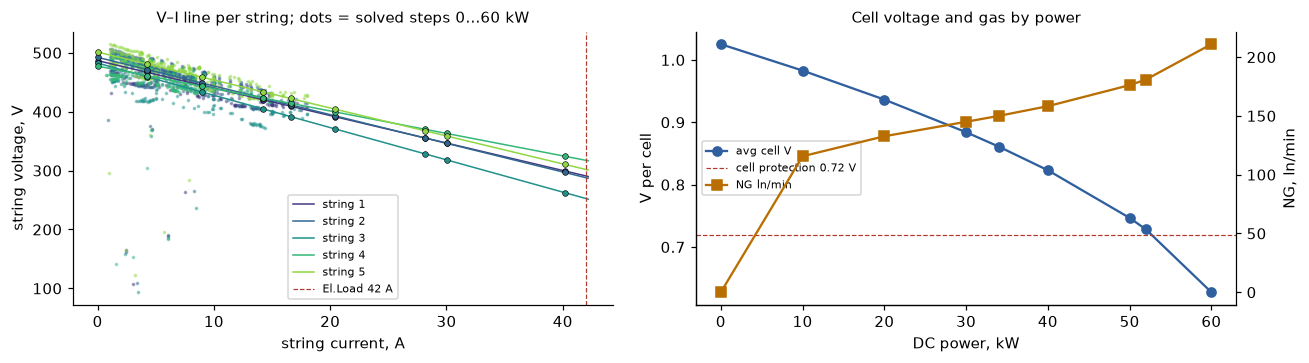

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
vi = e.attrs["VI"]
I_line = np.linspace(0, e[[f"I_{k}_A" for k in range(1, 6)]].values.max() * 1.05, 2)
for k, (v, i) in enumerate(zip(rp.VOLT, rp.CURR), start=1):
    c = plt.cm.viridis(k / 6)
    axs[0].scatter(d[i], d[v], s=2, color=c, alpha=0.4)
    r = vi.iloc[k - 1]
    axs[0].plot(I_line, r.V_at_0A + r.V_per_A * I_line, color=c, lw=1, label=f"string {k}")
    axs[0].scatter(e[f"I_{k}_A"], e[f"V_{k}_V"], s=14, color=c, edgecolor="k", lw=0.4, zorder=3)
axs[0].axvline(42, color=RED, lw=0.8, ls="--", label="El.Load 42 A")
axs[0].set_xlabel("string current, A"); axs[0].set_ylabel("string voltage, V"); axs[0].legend(fontsize=7)
axs[0].set_title("V–I line per string; dots = solved steps 0…60 kW", fontsize=10)

ax2 = axs[1]
ax2.plot(e.P_kW, e.V_cell_avg, "o-", color=BLUE, label="avg cell V")
ax2.axhline(0.72, color=RED, lw=0.8, ls="--", label="cell protection 0.72 V")
ax2.set_xlabel("DC power, kW"); ax2.set_ylabel("V per cell")
ax3 = ax2.twinx()
ax3.plot(e.P_kW, e.NG_lnmin, "s-", color=ORANGE, label="NG ln/min")
ax3.set_ylabel("NG, ln/min")
ax3.spines["right"].set_visible(True)
h, h3 = ax2.get_legend_handles_labels(), ax3.get_legend_handles_labels()
ax2.legend(h[0] + h3[0], h[1] + h3[1], fontsize=7, loc="center left")
ax2.set_title("Cell voltage and gas by power", fontsize=10)
plt.tight_layout()

## 4.5 R² of every part-load fit

R² = share of a sensor's part-load ups and downs that its straight line in power explains (1 = all, 0 = none),
computed on the minutes kept after the glitch drop. It covers every parameter that varies during part load: the
464 changing sensors (line `sensor = a + b·P`) and the 5 string V–I lines (`V = a + b·I`) behind the 60 kW
electrical point. Bands: strong ≥ 0.9, good 0.5–0.9, weak 0.1–0.5, none < 0.1.

In [10]:
BANDS = pd.cut(t.r2, [-np.inf, 0.1, 0.5, 0.9, np.inf], right=False, labels=["none <0.1", "weak 0.1-0.5", "good 0.5-0.9", "strong ≥0.9"])
summary = pd.crosstab(t.group, BANDS, margins=True, margins_name="all")
summary["median R²"] = t.groupby("group").r2.median().reindex(summary.index).fillna(t.r2.median())
assert summary.loc["all", "all"] == len(t)
summary.round(3)

r2,none <0.1,weak 0.1-0.5,good 0.5-0.9,strong ≥0.9,all,median R²
group,,,,,,
follows power,0,0,51,17,68,0.763
operator-set / no link,136,115,0,0,251,0.068
temperature / cell (lags power),72,73,0,0,145,0.102
all,208,188,51,17,464,0.126


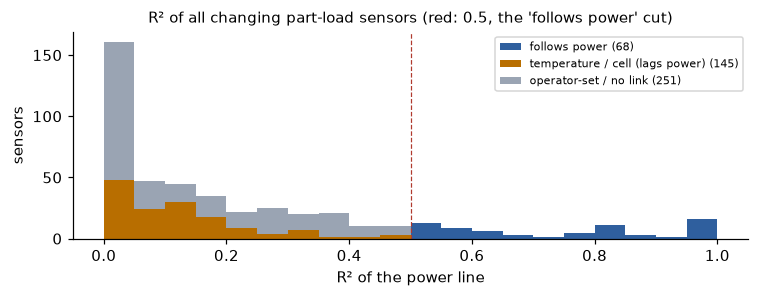

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(0, 1, 21)
ax.hist([t[t.group == g].r2.clip(0, 1) for g in colors], bins=bins, stacked=True, color=list(colors.values()),
        label=[f"{g} ({(t.group == g).sum()})" for g in colors])
ax.axvline(0.5, color=RED, lw=0.8, ls="--")
ax.set_xlabel("R² of the power line"); ax.set_ylabel("sensors"); ax.legend(fontsize=7)
ax.set_title("R² of all changing part-load sensors (red: 0.5, the 'follows power' cut)", fontsize=10)
plt.tight_layout()

In [12]:
# the 68 sensors that follow power, by kind
KIND = [("Actual_Power", "string power"), ("SP_TargetValue|SP_Analog", "current set point"),
        ("CurrentMon|OUT_Analog|rCurrMonitor", "string current"), ("rFU_Worst", "fuel use"), ("Uac", "inverter AC voltage"),
        ("VoltageMon|rVoltMonitor|TotalVoltage", "string voltage"), ("pi_EIR", "pi_EIR readings")]
fp = t[t.power_driven].copy()
fp["kind"] = "other"
for pat, k in KIND[::-1]:
    fp.loc[fp.sensor.str.contains(pat), "kind"] = k
fp.groupby("kind").r2.agg(["count", "min", "median", "max"]).sort_values("median", ascending=False).round(3)

,count,min,median,max
kind,,,,
string power,5,0.750,0.989,0.995
string current,15,0.762,0.961,0.982
fuel use,5,0.694,0.889,0.930
current set point,10,0.829,0.829,0.830
pi_EIR readings,11,0.505,0.644,0.817
other,1,0.619,0.619,0.619
string voltage,12,0.507,0.564,0.603
inverter AC voltage,9,0.508,0.534,0.629


In [13]:
# string V–I lines (used for the 60 kW current/voltage, §4)
e.attrs["VI"][["string", "V_at_0A", "V_per_A", "r2"]].round(3)

,string,V_at_0A,V_per_A,r2
0,1,486.664,-4.662,0.653
1,2,492.271,-4.866,0.699
2,3,482.523,-5.476,0.541
3,4,477.357,-3.809,0.471
4,5,501.163,-4.746,0.744


In [14]:
# every changing sensor, best fit first (also in rated_power/sensor_extrapolation.csv, column r2)
with pd.option_context("display.max_rows", None):
    display(t.sort_values("r2", ascending=False)[["sensor", "group", "r2", "loro_err_pct_of_range", "n_min"]]
            .reset_index(drop=True).round(3))

,sensor,group,r2,loro_err_pct_of_range,n_min
0,EIRC_41_Actual_Power,follows power,0.995,2.137,237
1,EIRC_43_Actual_Power,follows power,0.995,2.573,239
2,EIRC_42_Actual_Power,follows power,0.989,3.879,240
3,EIRC_41_CurrentMon,follows power,0.982,4.574,240
4,EIRC_41_OUT_Analog,follows power,0.982,4.572,240
5,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,0.982,4.204,265
6,EIRC_45_Actual_Power,follows power,0.976,5.550,241
7,EIRC_43_OUT_Analog,follows power,0.966,6.992,241
8,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,0.966,6.239,266
9,EIRC_43_CurrentMon,follows power,0.964,6.983,242


## 4.6 Curve fits: can a curve or a time lag beat the straight line?

Same part-load minutes and glitch drop as §2. Five model families per sensor (code: `scripts/rated_power_curves.py`):

| Model | Formula | Idea |
|---|---|---|
| line | y = a + b·P | §2 |
| quadratic | y = a + b·P + c·P² | bends with power |
| lag τ | y = a + b·L | L = power through a first-order lag, time constant τ, 0 at each run start (runs start in hot standby) |
| power + lag τ | y = a + b·P + c·L | a fast part and a slow part |
| start + lag τ | y = y0 + b·P + c·L | y0 = the reading at the run's first minute: the sensor's starting state is known |

τ ∈ 5, 10, 20, 40, 80, 160, 320 min. Each sensor keeps the model with the **lowest leave-one-run-out MAE** (fit on 9
runs, predict the whole 10th), so a curve only wins if it also predicts a run it never saw; ties go to the simpler model.
R² and MAE are also shown on the fitted minutes. MAE is in the sensor's own unit.

**Limit for 60 kW:** runs last 8–44 min, so slow lags are poorly pinned, and "start + lag" needs a starting reading.
At 60 kW the lag models are read at steady state (L = P = 60), "start + lag" from the median run start. Read
blindly, some best curves land far off at 60 kW (320-min lags fitted on ≤ 44-min runs: 2496 °C stack TCs, −2985 Ω
insulation), so §4.7 uses the best curve whose 60 kW value is plausible.

In [15]:
import rated_power_curves as rc
rc.self_check()
res, fits = rc.fit_all(d, t)
res["family"] = res.best_model.str.replace(r" \d+ min", "", regex=True)
g = res.groupby("group")
pd.DataFrame({"sensors": g.size(), "median R² line": g.r2_line.median(), "median R² best": g.r2_best.median(),
              "median MAE cut %": g.apply(lambda x: (100 * (1 - x.mae_best / x.mae_line)).median()),
              "median held-out MAE cut %": g.loro_mae_cut_pct.median(),
              "line still best": g.apply(lambda x: (x.best_model == "line").sum())}).round(3)

,sensors,median R² line,median R² best,median MAE cut %,median held-out MAE cut %,line still best
group,,,,,,
follows power,68,0.763,0.828,15.145,12.361,10
operator-set / no link,251,0.068,0.783,52.214,52.772,10
temperature / cell (lags power),145,0.102,0.553,34.769,37.823,2


In [16]:
pd.crosstab(res.group, res.family, margins=True, margins_name="all")

family,lag,line,power + lag,quadratic,start + lag,all
group,,,,,,
follows power,0,10,5,16,37,68
operator-set / no link,8,10,11,6,216,251
temperature / cell (lags power),17,2,0,12,114,145
all,25,22,16,34,367,464


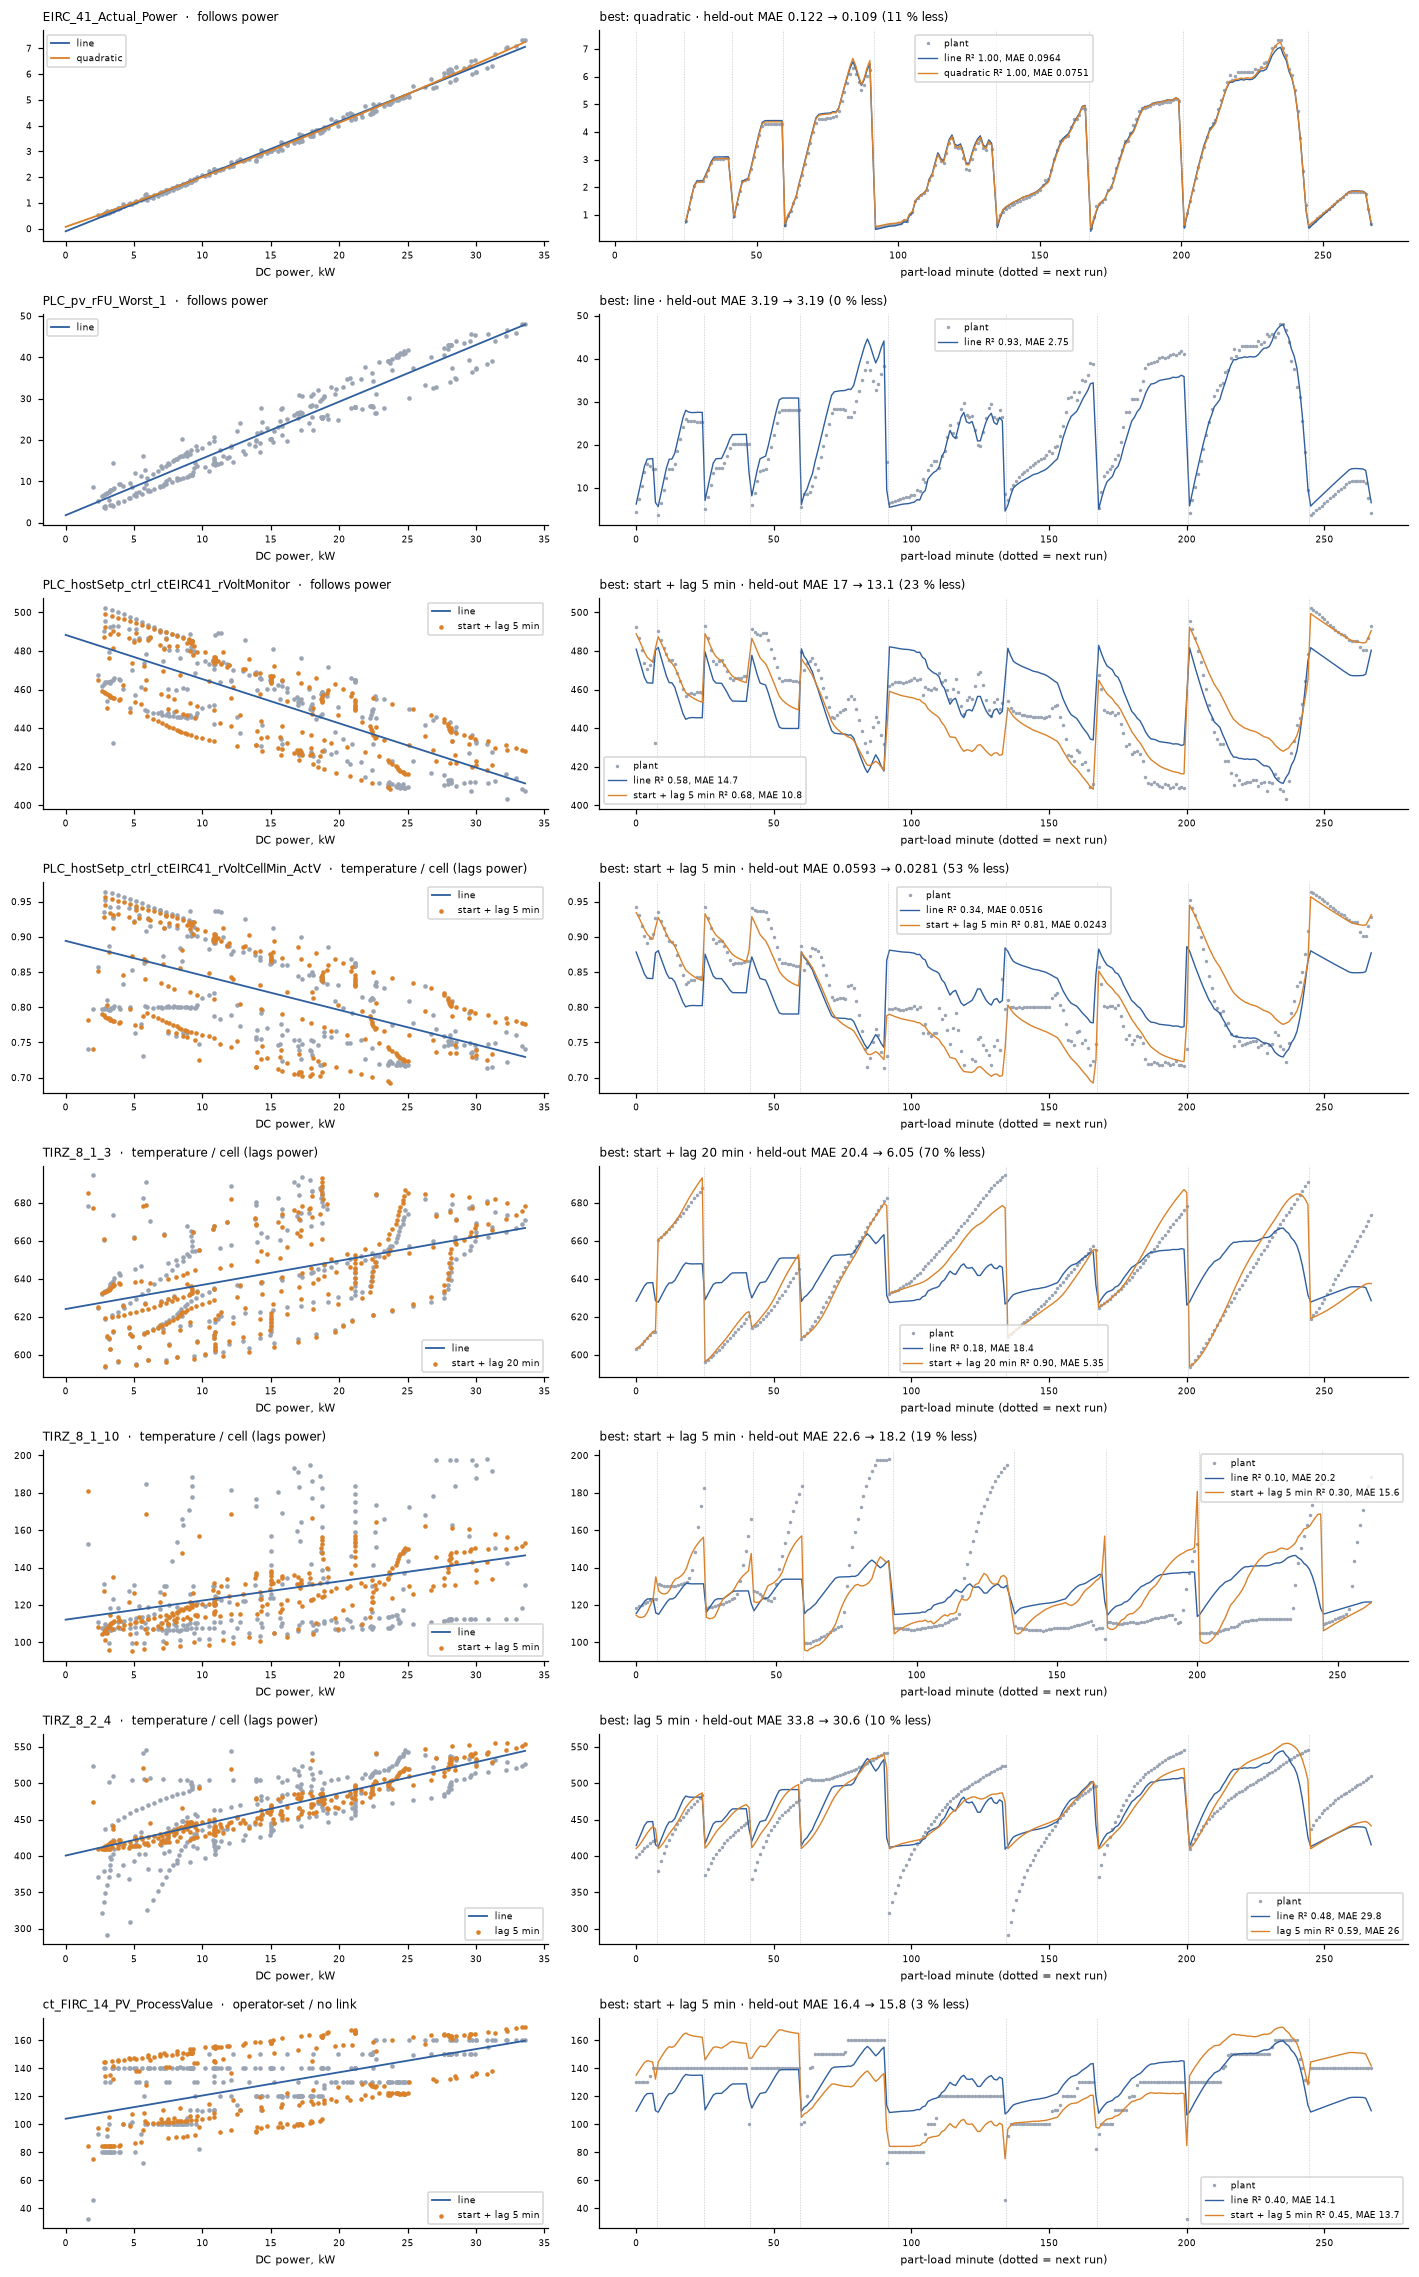

In [17]:
EXAMPLES = ["EIRC_41_Actual_Power", "PLC_pv_rFU_Worst_1", "PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor",
            "PLC_hostSetp_ctrl_ctEIRC41_rVoltCellMin_ActV", "TIRZ_8_1_3", "TIRZ_8_1_10", "TIRZ_8_2_4", "ct_FIRC_14_PV_ProcessValue"]
fig, axs = plt.subplots(len(EXAMPLES), 2, figsize=(13, 2.6 * len(EXAMPLES)), gridspec_kw={"width_ratios": [1, 1.6]})
rc.plot_rows(d, res, fits, EXAMPLES, axs)
plt.tight_layout()

In [18]:
# 60 kW: best curve vs straight line, in units of the sensor's seen part-load range
span = (t.set_index("sensor").seen_max - t.set_index("sensor").seen_min).reindex(res.sensor).values
res["gap_60kW_ranges"] = (res.at_60kW_best - res.at_60kW_line).abs() / span
print("sensors whose best curve lands > 1 seen range from the line at 60 kW:", (res.gap_60kW_ranges > 1).sum(),
      res[res.gap_60kW_ranges > 1].family.value_counts().to_dict())
res.set_index("sensor").loc[EXAMPLES, ["best_model", "r2_line", "r2_best", "loro_mae_line", "loro_mae_best",
                                       "at_60kW_line", "at_60kW_best"]].round(3)

sensors whose best curve lands > 1 seen range from the line at 60 kW: 117 {'start + lag': 98, 'quadratic': 15, 'lag': 4}


,best_model,r2_line,r2_best,loro_mae_line,loro_mae_best,at_60kW_line,at_60kW_best
sensor,,,,,,,
EIRC_41_Actual_Power,quadratic,0.995,0.996,0.122,0.109,12.683,14.243
PLC_pv_rFU_Worst_1,line,0.930,0.930,3.194,3.194,84.166,84.166
PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor,start + lag 5 min,0.578,0.679,17.002,13.115,350.859,365.352
PLC_hostSetp_ctrl_ctEIRC41_rVoltCellMin_ActV,start + lag 5 min,0.339,0.808,0.059,0.028,0.600,0.606
TIRZ_8_1_3,start + lag 20 min,0.182,0.900,20.382,6.053,700.313,841.624
TIRZ_8_1_10,start + lag 5 min,0.102,0.301,22.594,18.201,173.544,212.385
TIRZ_8_2_4,lag 5 min,0.476,0.595,33.823,30.601,657.606,688.618
ct_FIRC_14_PV_ProcessValue,start + lag 5 min,0.399,0.446,16.409,15.841,203.561,197.889


In [19]:
# every changing sensor (all 464), by group then best R²
with pd.option_context("display.max_rows", None):
    display(res.sort_values(["group", "r2_best"], ascending=[True, False])
            [["sensor", "group", "best_model", "r2_line", "r2_best", "mae_line", "mae_best", "loro_mae_line", "loro_mae_best"]]
            .reset_index(drop=True).round(3))

,sensor,group,best_model,r2_line,r2_best,mae_line,mae_best,loro_mae_line,loro_mae_best
0,EIRC_41_Actual_Power,follows power,quadratic,0.995,0.996,9.600000e-02,7.500000e-02,1.220000e-01,1.090000e-01
1,EIRC_43_Actual_Power,follows power,power + lag 80 min,0.995,0.995,1.080000e-01,1.030000e-01,1.340000e-01,1.310000e-01
2,EIRC_42_Actual_Power,follows power,power + lag 10 min,0.989,0.989,1.690000e-01,1.660000e-01,2.050000e-01,2.040000e-01
3,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,quadratic,0.982,0.988,4.790000e-01,3.450000e-01,5.850000e-01,4.640000e-01
4,EIRC_41_OUT_Analog,follows power,quadratic,0.982,0.988,5.270000e-01,3.960000e-01,6.550000e-01,5.450000e-01
5,EIRC_41_CurrentMon,follows power,quadratic,0.982,0.988,4.850000e-01,3.660000e-01,6.020000e-01,5.020000e-01
6,EIRC_45_Actual_Power,follows power,power + lag 5 min,0.976,0.978,2.330000e-01,2.300000e-01,2.880000e-01,2.870000e-01
7,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,quadratic,0.966,0.972,6.930000e-01,5.910000e-01,8.090000e-01,7.150000e-01
8,EIRC_43_OUT_Analog,follows power,quadratic,0.966,0.972,7.590000e-01,6.600000e-01,9.030000e-01,8.180000e-01
9,EIRC_43_CurrentMon,follows power,quadratic,0.964,0.970,7.060000e-01,6.210000e-01,8.370000e-01,7.650000e-01


In [20]:
# plots of all 464 sensors (6 per A4 page, same layout as above) + the table
res.to_csv(rp.OUT / "curve_fits.csv", index=False)
rc.plot_all(d, res, fits, rp.OUT / "curve_fit_plots.pdf")
print("written:", rp.OUT / "curve_fits.csv", "and", rp.OUT / "curve_fit_plots.pdf")

written: C:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\rated_power\curve_fits.csv and C:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\rated_power\curve_fit_plots.pdf


## 4.7 Extrapolation with the best curve

Each sensor's `use_<p>kW` (0 … 60 kW) now comes from its **best plausible curve** (column `model`): the model with the
lowest leave-one-run-out MAE whose 60 kW value stays within one seen part-load range below the lowest / above the
highest reading (a straight line through the data lands about 0.8 range past it); otherwise the next best, the line
as last resort. Lag models are read at steady state (L = P), "start + lag" from the median run start.
String V and I stay on the V–I solution (so Σ V·I = P exactly) and gas on Faraday, now at the best-curve fuel use.
The notes (trips crossed, actuators past 0 / 100 %) are rebuilt from the new values.

In [21]:
rc.apply_best(t, fits)
rp.add_notes(t)
e = rp.electrical(d, t)          # V, I and gas on top, fuel use from the best curves
assert np.allclose(e.P_check_kW, e.P_kW, atol=0.01)
print("extrapolation model = best-fit model for", (res.extrap_model == res.best_model).sum(), "of", len(res), "sensors;",
      ((res.extrap_model == "line") & (res.best_model != "line")).sum(), "fell back to the line")
print("string power sensors at 60 kW add up to",
      round(t[t.sensor.str.match(r"EIRC_4\d_Actual_Power")].use_60kW.sum(), 1), "kW")
g = res.groupby("group")
pd.DataFrame({"median R² line": g.r2_line.median(), "median R² best": g.r2_best.median(), "median R² used": g.r2_extrap.median(),
              "median held-out MAE cut % (used vs line)": g.apply(lambda x: (100 * (1 - x.loro_mae_extrap / x.loro_mae_line)).median())}).round(3)

extrapolation model = best-fit model for 345 of 464 sensors; 6 fell back to the line
string power sensors at 60 kW add up to 60.7 kW


,median R² line,median R² best,median R² used,median held-out MAE cut % (used vs line)
group,,,,
follows power,0.763,0.828,0.829,9.194
operator-set / no link,0.068,0.783,0.783,52.515
temperature / cell (lags power),0.102,0.553,0.540,37.823


In [22]:
# 60 kW: straight line (§2) vs best curve now used
cmp = t.set_index("sensor").loc[EXAMPLES + ["TIRC_5_09", "TIR_4_6_27"], ["model", "seen_min", "seen_max", "at_60kW", "use_60kW", "note"]]
cmp.rename(columns={"at_60kW": "line at 60 kW", "use_60kW": "used at 60 kW"}).round(2)

,model,seen_min,seen_max,line at 60 kW,used at 60 kW,note
sensor,,,,,,
EIRC_41_Actual_Power,line,0.53,7.33,12.68,12.68,
PLC_pv_rFU_Worst_1,line,3.66,48.13,84.17,84.17,
PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor,V-I solved,403.20,502.46,350.86,299.35,V-I solved so sum V*I = P (electrical_60kW.csv)
PLC_hostSetp_ctrl_ctEIRC41_rVoltCellMin_ActV,start + lag 5 min,0.71,0.96,0.60,0.61,plant cell protection (0.72 V) stops load before this;
TIRZ_8_1_3,start + lag 10 min,593.58,694.39,700.31,787.45,crosses trip 720 at 37 kW; heat balance (rated-power work 2026-11-05): no steady point under the 720 trip; trips at ...
TIRZ_8_1_10,start + lag 5 min,99.82,197.88,173.54,212.39,crosses trip 200 at 53 kW; heat balance: exhaust 200 trip reached in 3 of 4 rated-power cases
TIRZ_8_2_4,lag 5 min,291.29,545.25,657.61,688.62,
ct_FIRC_14_PV_ProcessValue,Faraday from solved current,32.50,160.09,203.56,210.09,gas by Faraday from solved currents at the fuel-use trend (operator steps hide the link)
TIRC_5_09,lag 320 min,627.64,805.81,733.67,679.21,


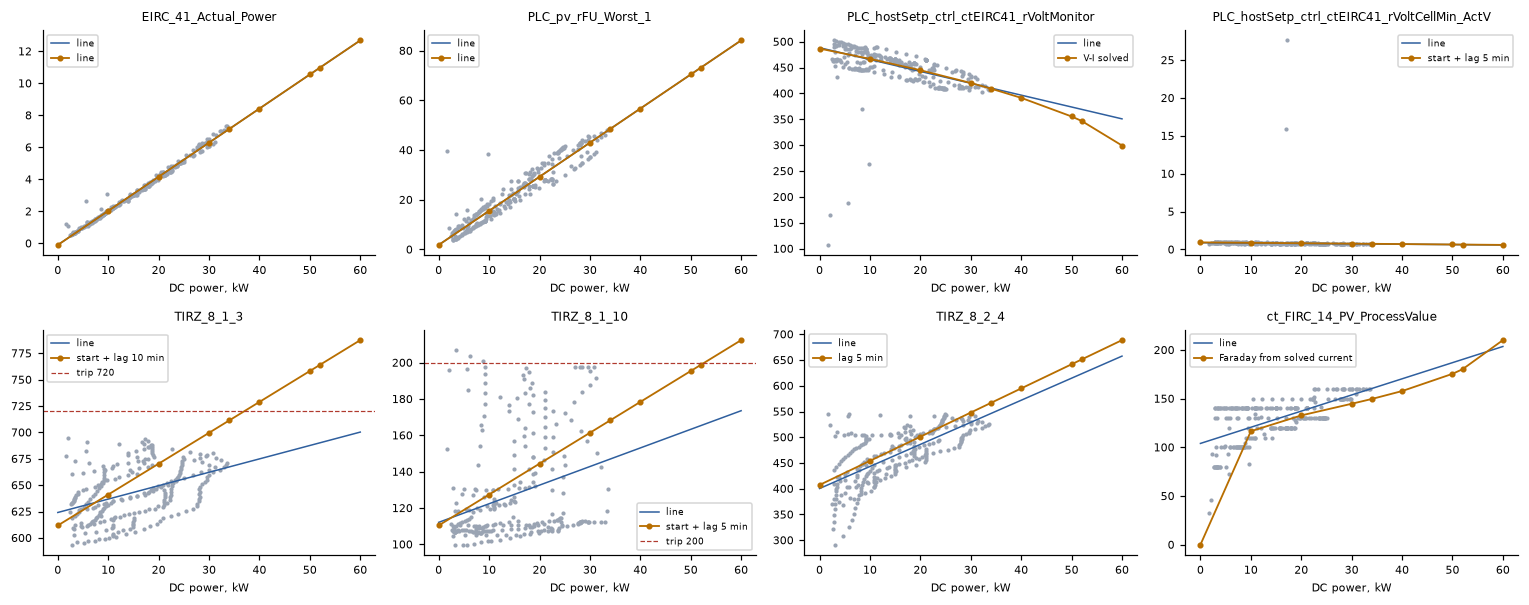

In [23]:
# the used curves from 0 to 60 kW (steady state) for the examples, part-load minutes in grey
fig, axs = plt.subplots(2, 4, figsize=(14, 5.6))
T = t.set_index("sensor")
for ax, s in zip(axs.flat, EXAMPLES):
    ax.scatter(d.P_dc_kW, d[s], s=3, color=GRAY)
    ax.plot(rp.STEPS, T.loc[s, [f"at_{p}kW" for p in rp.STEPS]], color=BLUE, lw=1, label="line")
    ax.plot(rp.STEPS, T.loc[s, [f"use_{p}kW" for p in rp.STEPS]], "o-", color=ORANGE, ms=3, lw=1.2, label=T.loc[s, "model"])
    if s in rp.LIMITS:
        ax.axhline(rp.LIMITS[s], color=RED, lw=0.8, ls="--", label=f"trip {rp.LIMITS[s]:.0f}")
    ax.set_title(s, fontsize=8); ax.legend(fontsize=6); ax.tick_params(labelsize=7); ax.set_xlabel("DC power, kW", fontsize=7)
plt.tight_layout()

## 5. Notes and limits

Sensors where the straight line runs into something the plant would not allow: a trip (stack TIRZ 8.1.3 at 720 °C,
exhaust TIRZ 8.1.10 at 200 °C), the 0.72 V cell protection, or an actuator past 0 / 100 %.

In [24]:
t[t.note != ""][["sensor", "group", "at_34kW", "use_rated", "use_60kW", "note"]].round(2)

,sensor,group,at_34kW,use_rated,use_60kW,note
272,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,16.83,30.00,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
278,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,17.11,30.00,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
284,PLC_hostSetp_ctrl_ctEIRC43_rCurrMonitor,follows power,17.11,30.00,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
296,PLC_hostSetp_ctrl_ctEIRC45_rCurrMonitor,follows power,16.76,30.00,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
290,PLC_hostSetp_ctrl_ctEIRC44_rCurrMonitor,follows power,11.61,30.00,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
295,PLC_hostSetp_ctrl_ctEIRC45_rVoltMonitor,follows power,424.90,358.76,310.49,V-I solved so sum V*I = P (electrical_60kW.csv)
289,PLC_hostSetp_ctrl_ctEIRC44_rVoltMonitor,follows power,426.73,363.08,324.34,V-I solved so sum V*I = P (electrical_60kW.csv)
271,PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor,follows power,410.42,346.77,299.35,V-I solved so sum V*I = P (electrical_60kW.csv)
277,PLC_hostSetp_ctrl_ctEIRC42_rVoltMonitor,follows power,412.94,346.27,296.78,V-I solved so sum V*I = P (electrical_60kW.csv)
256,ct_FIRC_14_PV_ProcessValue,operator-set / no link,160.43,180.21,210.09,gas by Faraday from solved currents at the fuel-use trend (operator steps hide the link)


## 6. Save outputs

Same files as `python scripts/rated_power_extrapolation.py`.

In [25]:
rp.OUT.mkdir(exist_ok=True)
d.to_parquet(rp.OUT / "pl_minutes.parquet")
e.to_csv(rp.OUT / "electrical_60kW.csv", index=False)
e.attrs["VI"].to_csv(rp.OUT / "string_vi_fit.csv", index=False)
t.to_csv(rp.OUT / "sensor_extrapolation.csv", index=False)
t.round(4).to_excel(rp.OUT / "sensor_extrapolation.xlsx", index=False)
print("written to", rp.OUT)

written to C:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\rated_power
